In [2]:
import sys
sys.path.append("../")
from analysis import System as syst
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import periodogram, welch
from scipy.optimize import curve_fit as fit
def signal(t, a, b, c):
    return a * np.sin(np.pi * 1.08e5 * t + b) ** 2 + c
def find_nearest(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return array[idx]
def find_idx(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return idx
def pp(arr, d, i):
    arr.set_data(ind = i)
    d.apply("time_gate", tmin = 0, tmax = 5e-5, inplace = True)
    # d.apply("detrend", mode = "linear", inplace = True)
    # d.apply("filter", cutoff = [50e3, 150e3], btype = "bandpass", inplace = True)

In [3]:
piezo = syst("piezo", ["../../data/20251215/stroke_dist_" + str(x) + "vpp_109kHz/iter_" + str(y) + ".tdms" for x in range(1, 11) for y in range(29)], channel = "X", set_data = True)

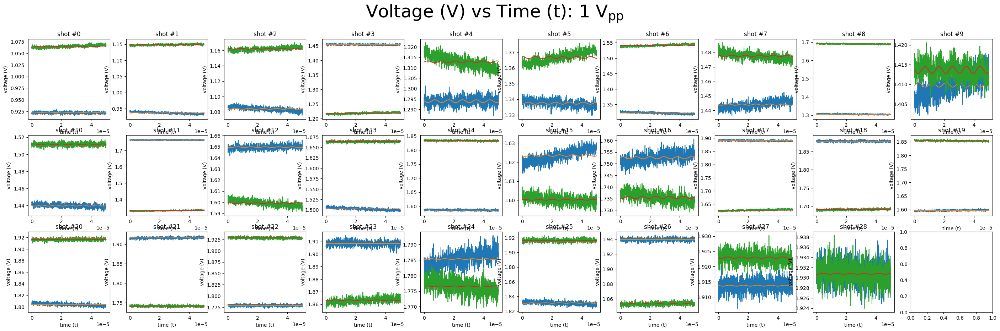

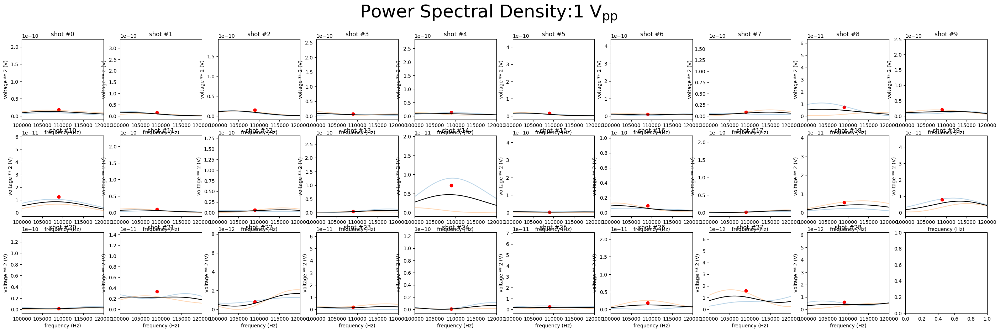

<Figure size 640x480 with 0 Axes>

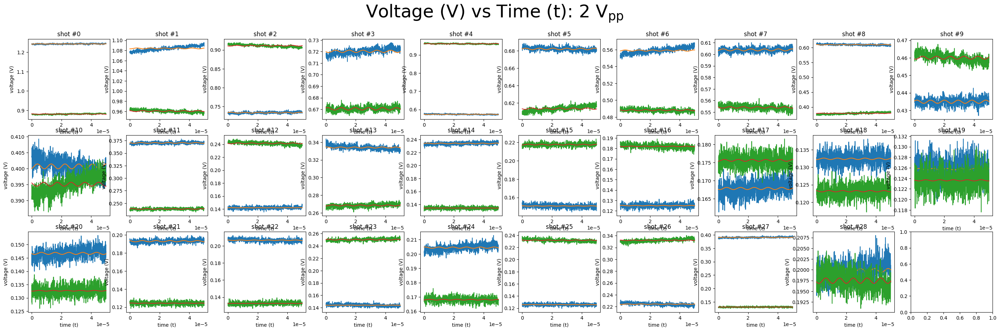

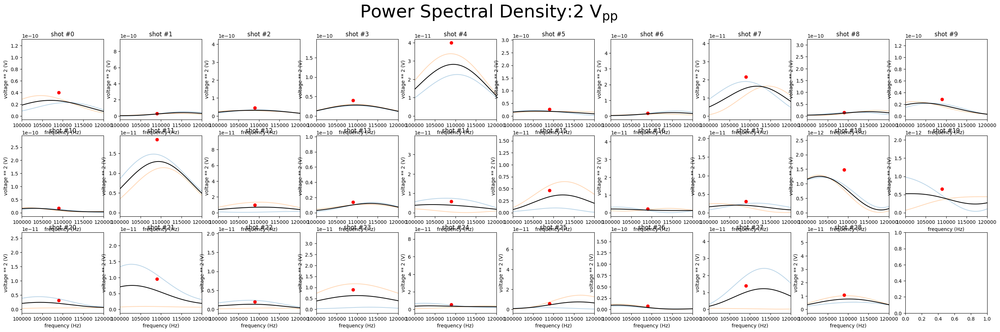

<Figure size 640x480 with 0 Axes>

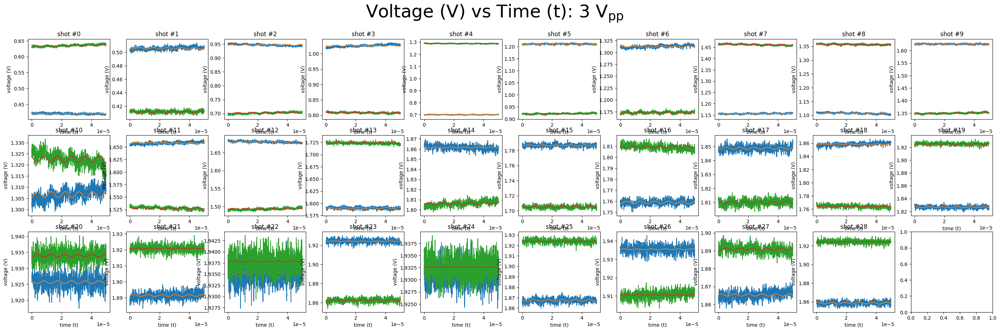

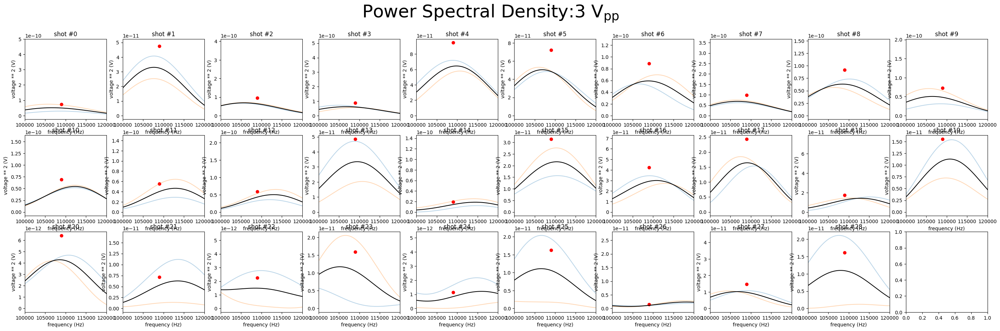

<Figure size 640x480 with 0 Axes>

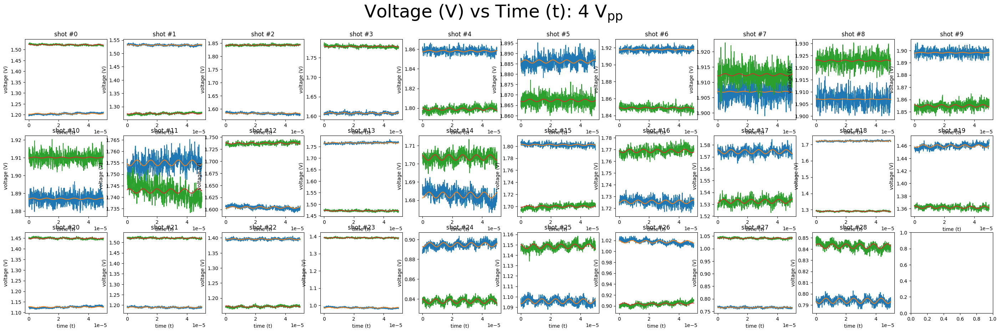

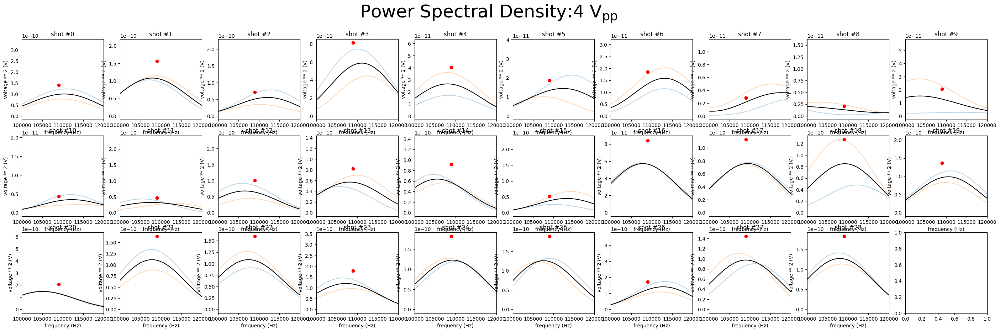

<Figure size 640x480 with 0 Axes>

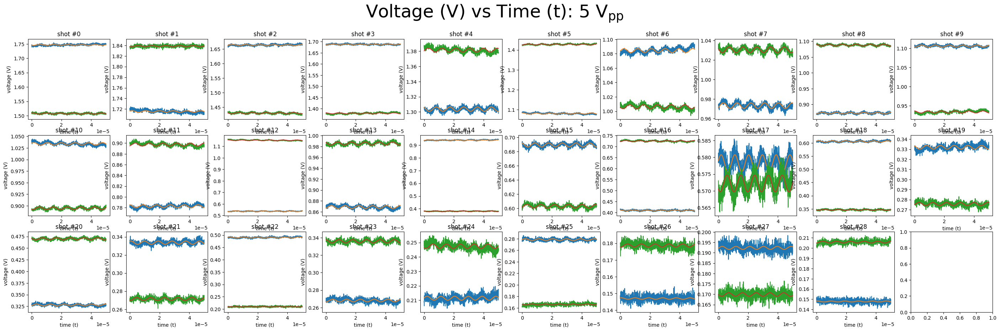

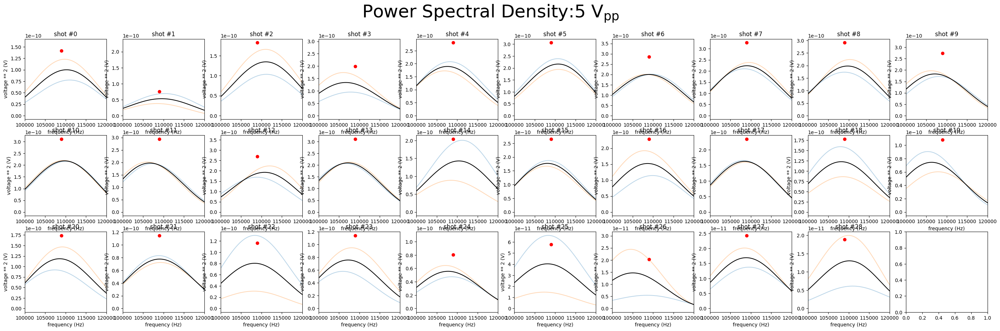

<Figure size 640x480 with 0 Axes>

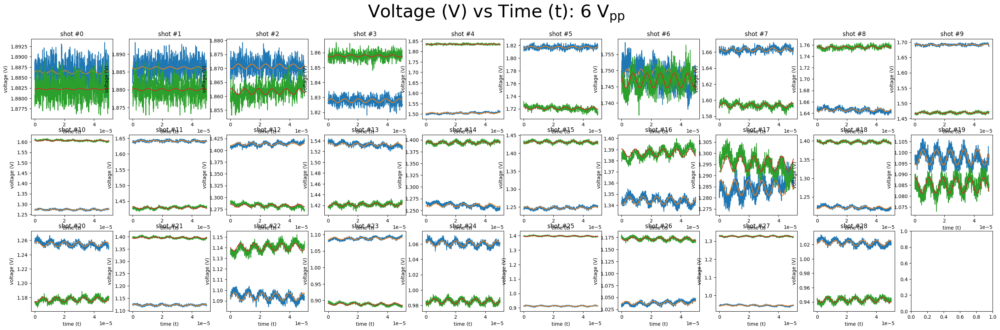

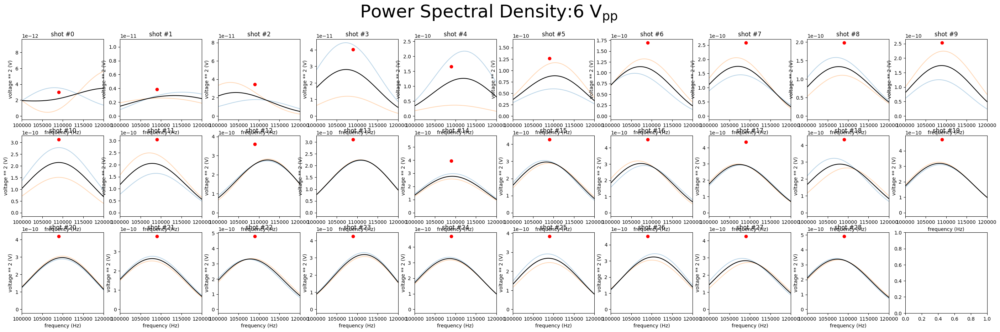

<Figure size 640x480 with 0 Axes>

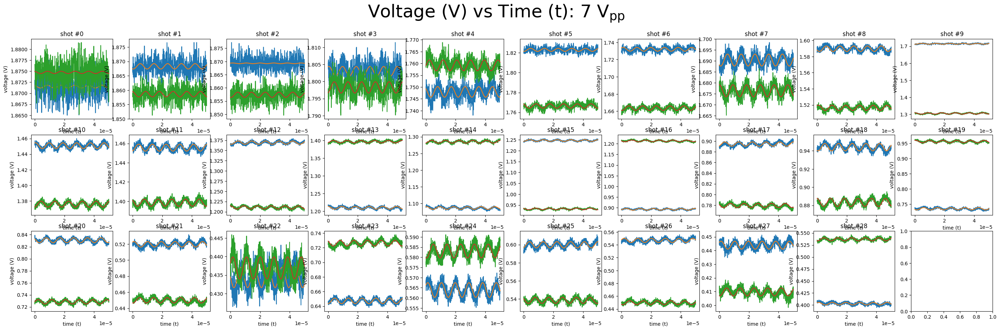

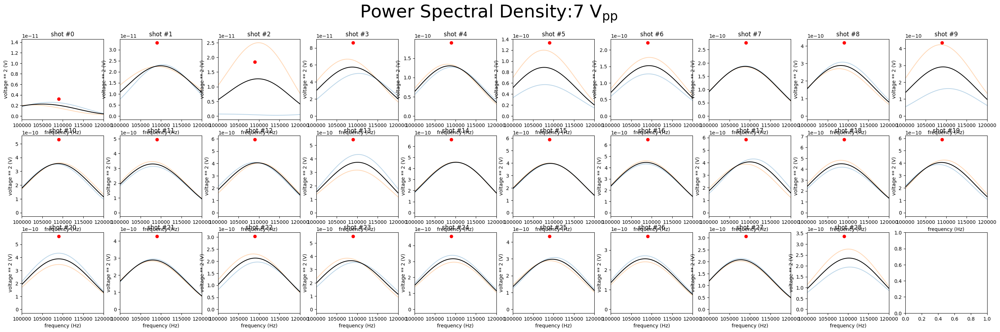

<Figure size 640x480 with 0 Axes>

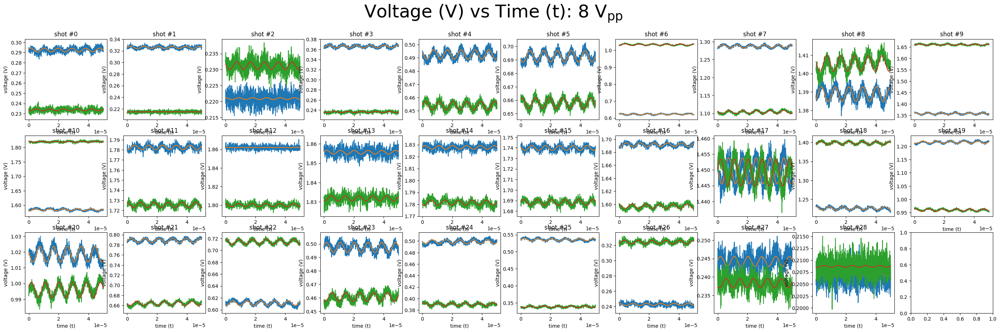

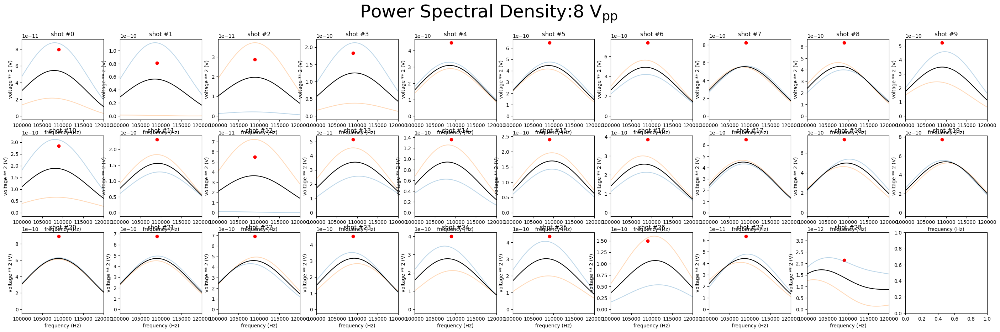

<Figure size 640x480 with 0 Axes>

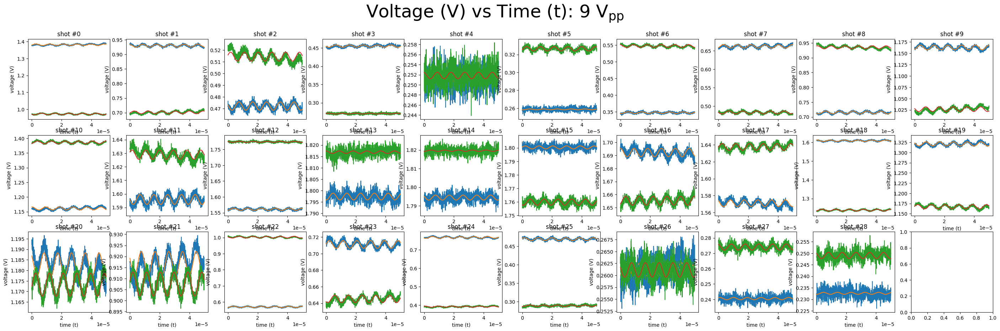

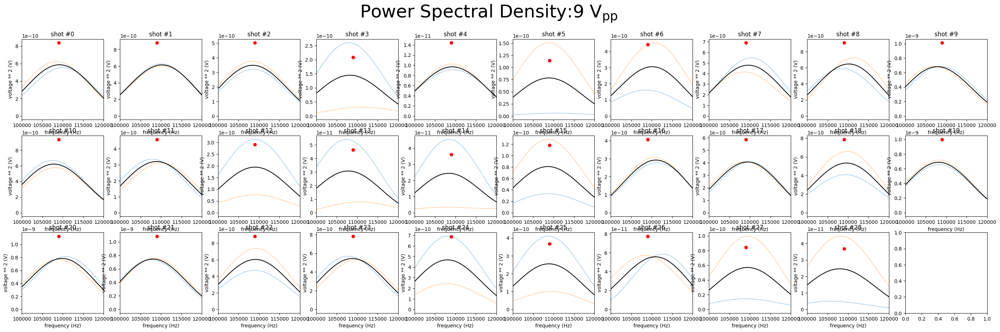

<Figure size 640x480 with 0 Axes>

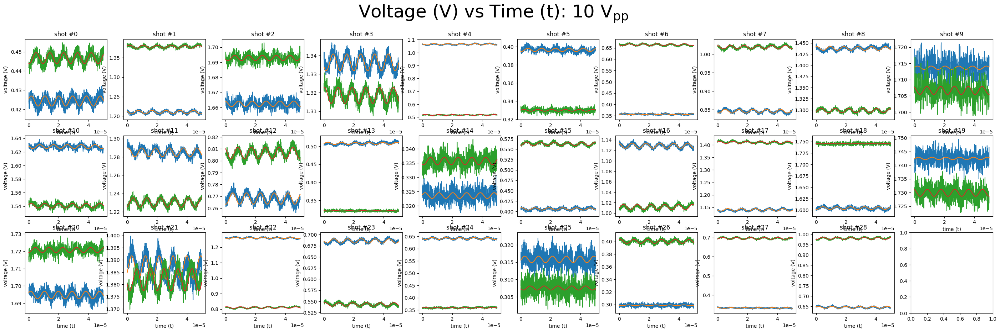

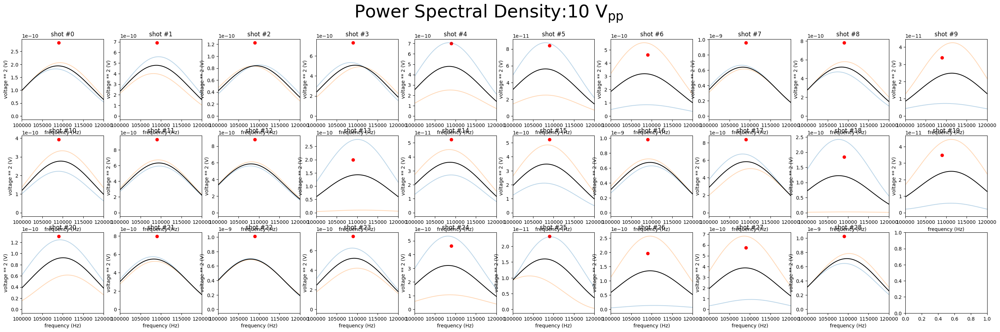

<Figure size 640x480 with 0 Axes>

In [4]:
freq = 1.09e5
cpsds = []
dpsds = []
amplitudes = []
for count in range(1, 11):
    calc_psd = []
    data_psd = []
    amps = []
    fig1, ax1 = plt.subplots(3, 10, figsize = (35, 10))
    fig1.suptitle(r"Voltage (V) vs Time (t): " + str(count) + r" V$_{\text{pp}}$", fontsize = 36)
    fig2, ax2 = plt.subplots(3, 10, figsize = (35, 10))
    fig2.suptitle(r"Power Spectral Density:" + str(count) + r" V$_{\text{pp}}$", fontsize = 36)
    piezo = syst("piezo", ["../../data/20251215/stroke_dist_" + str(count) + "vpp_109kHz/iter_" + str(y) + ".tdms" for y in range(29)], channel = "X", set_data = True)
    for i, d in enumerate(piezo.get_data()):
        sig = 0
        p = []
        a = []
        pp(piezo, d, i)
        ax1[i // 10][i % 10].plot(d.collection[0].t, d.collection[0].x)
        sig = fit(signal, d.collection[0].t, d.collection[0].x, [0.005, 0, 0])
        a.append(np.abs(sig[0][0]))
        # p.append(sig[0][0] ** 2 / (freq / (2 * np.pi)))
        p.append(sig[0][0] ** 2 / (freq))
        ax1[i // 10][i % 10].plot(d.collection[0].t, signal(d.collection[0].t, sig[0][0], sig[0][1], sig[0][2]))
        
        ax1[i // 10][i % 10].plot(d.collection[1].t, d.collection[1].x)
        sig = fit(signal, d.collection[1].t, d.collection[1].x, [0.005, 0, 0])
        a.append(np.abs(sig[0][0]))
        # p.append(sig[0][0] ** 2 / (freq / (2 * np.pi)))
        p.append(sig[0][0] ** 2 / (freq))
        ax1[i // 10][i % 10].plot(d.collection[1].t, signal(d.collection[1].t, sig[0][0], sig[0][1], sig[0][2]))
        
        ax1[i // 10][i % 10].set_xlabel("time (t)")
        ax1[i // 10][i % 10].set_ylabel("voltage (V)")
        ax1[i // 10][i % 10].set_title("shot #" + str(i))

        calc_psd.append(p)
        amps.append(a)
        
        p = []
        pp(piezo, d, i)
        f, x = periodogram(d.collection[0].x, piezo.get_data()[i].r, nfft = 1e6)
        p.append(x[find_idx(f, find_nearest(f, freq))])
        ax2[i // 10][i % 10].plot(f, x, alpha = 0.3)
        avg = np.array(x)
        
        f, x = periodogram(d.collection[1].x, piezo.get_data()[i].r, nfft = 1e6)
        p.append(x[find_idx(f, find_nearest(f, freq))])
        ax2[i // 10][i % 10].plot(f, x, alpha = 0.3)
        
        avg = (avg + x) / 2
        ax2[i // 10][i % 10].plot(f, avg, c = "k")
        ax2[i // 10][i % 10].scatter(freq, np.mean(calc_psd[-1]), c = "r")

        ax2[i // 10][i % 10].set_xlabel("frequency (Hz)")
        ax2[i // 10][i % 10].set_ylabel("voltage ** 2 (V)")
        ax2[i // 10][i % 10].set_title("shot #" + str(i))
        ax2[i // 10][i % 10].set_xlim(1e5, 1.2e5)
        
        data_psd.append(p)

    plt.show()
    cpsds.append(calc_psd)
    dpsds.append(data_psd)
    amplitudes.append(amps)
    plt.tight_layout()
    plt.show()

In [5]:
peaks = syst("piezo", ["../../data/20251215/peaks/iter_" + str(y) + ".tdms" for y in range(29)], channel = "X", set_data = True)

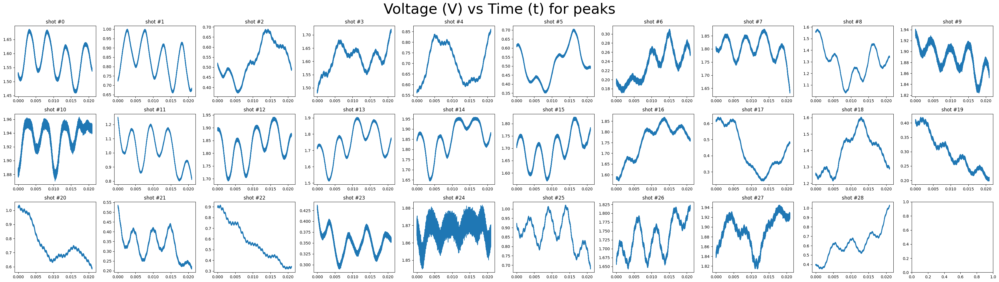

In [6]:
fig, ax = plt.subplots(3, 10, figsize = (35, 10))
fig.suptitle(r"Voltage (V) vs Time (t) for peaks", fontsize = 36)

X = np.array([])
for i, d in enumerate(peaks.get_data()):
    ax[i // 10][i % 10].set_title("shot #" + str(i))
    ax[i // 10][i % 10].plot(d.collection[0].t, d.collection[0].x)
    X = np.append(X, d.collection[0].x)

plt.tight_layout()
plt.show()

scaling_factor = np.max(X) - np.min(X)

In [8]:
def transform(x, factor):
    return 2 * (1064e-9 / 2 / np.pi)* np.arccos(-x / factor)

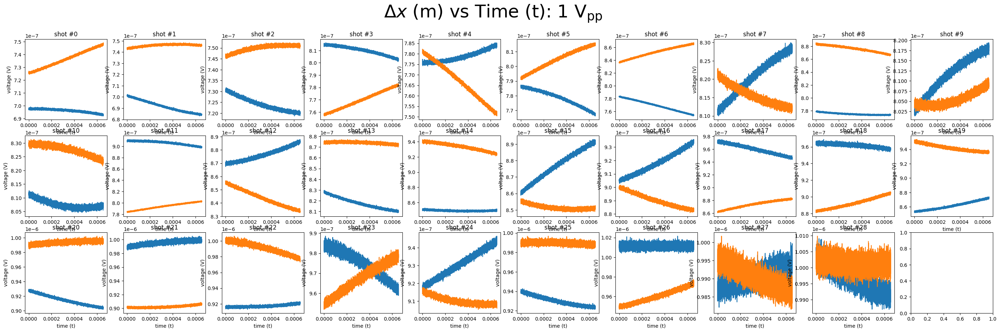

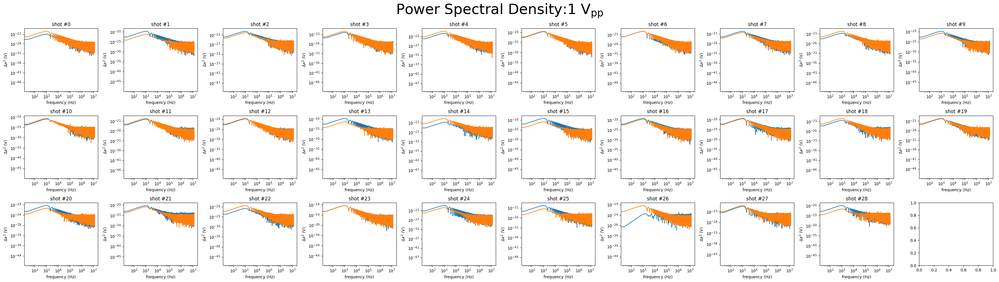

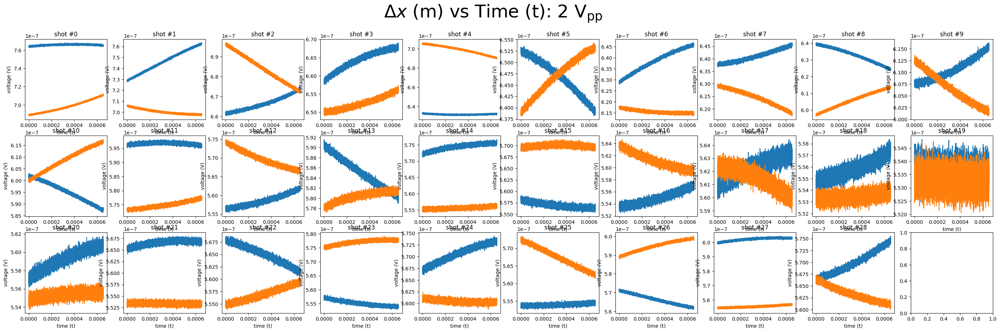

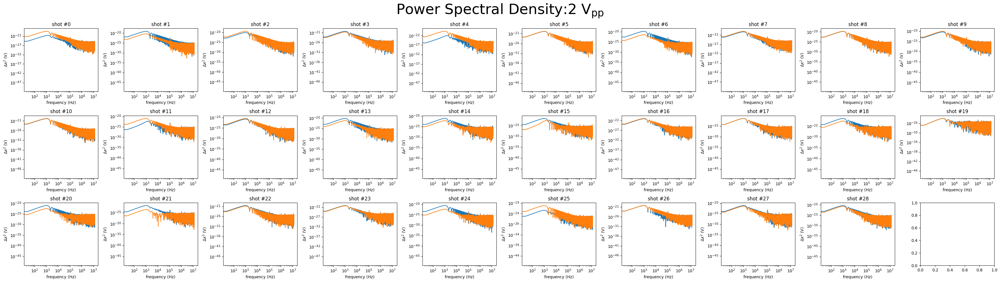

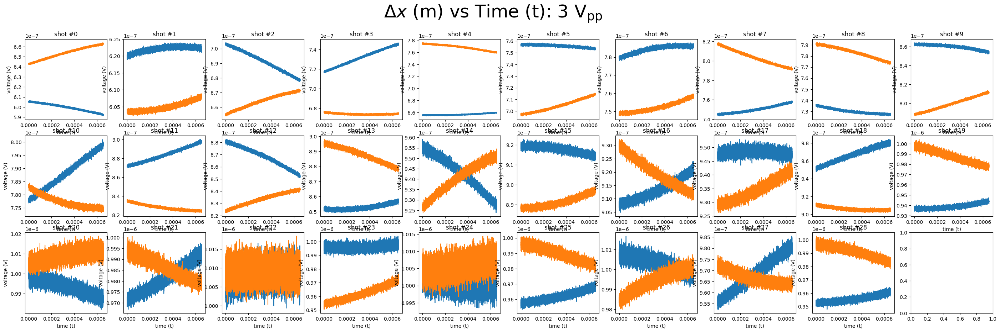

...

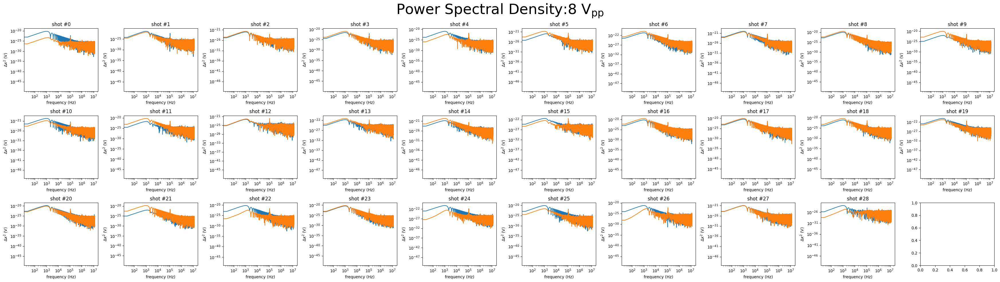

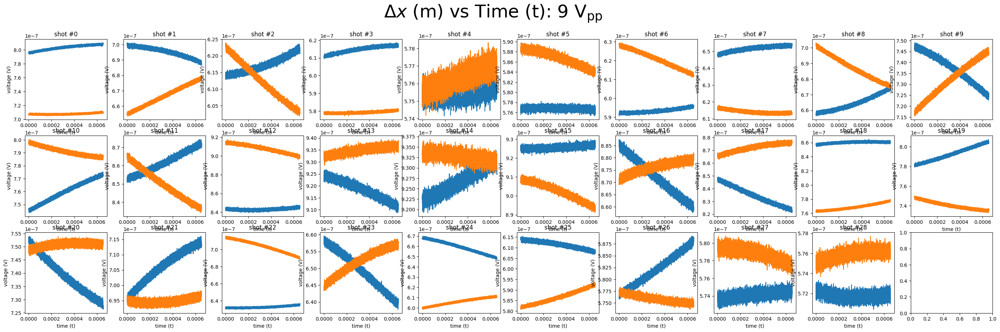

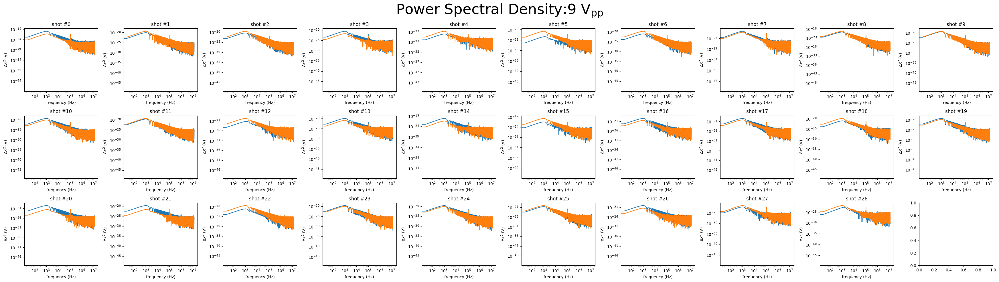

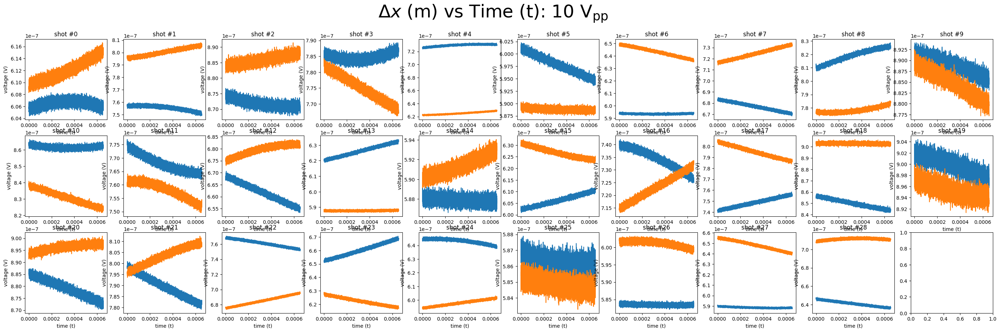

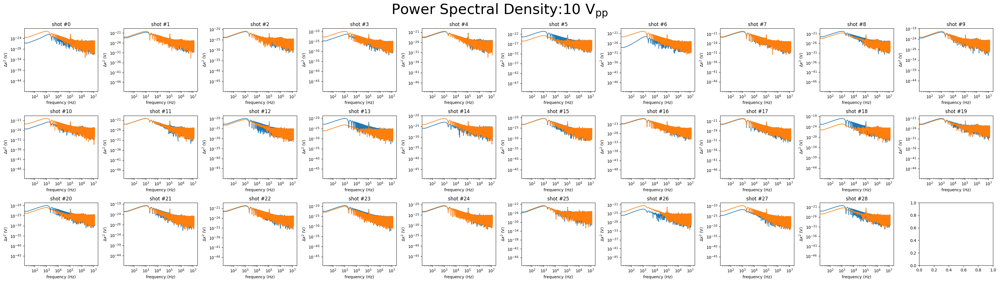

In [9]:
dpsds = []
for count in range(1, 11):
    data_psd = []
    piezo = syst("piezo", ["../../data/20251215/stroke_dist_" + str(count) + "vpp_109kHz/iter_" + str(y) + ".tdms" for y in range(29)], channel = "X", set_data = True)
    fig1, ax1 = plt.subplots(3, 10, figsize = (35, 10))
    fig1.suptitle(r"$\Delta x$ (m) vs Time (t): " + str(count) + r" V$_{\text{pp}}$", fontsize = 36)
    fig2, ax2 = plt.subplots(3, 10, figsize = (35, 10))
    fig2.suptitle(r"Power Spectral Density:" + str(count) + r" V$_{\text{pp}}$", fontsize = 36)
    for i, d in enumerate(piezo.get_data()):
        ax1[i // 10][i % 10].plot(d.collection[0].t, transform(d.collection[0].x, np.max(X)))
        ax1[i // 10][i % 10].plot(d.collection[1].t, transform(d.collection[1].x, np.max(X)))
        ax1[i // 10][i % 10].set_xlabel("time (t)")
        ax1[i // 10][i % 10].set_ylabel("voltage (V)")
        ax1[i // 10][i % 10].set_title("shot #" + str(i))

        p = []
        f, x = periodogram(transform(d.collection[0].x, np.max(X)), piezo.get_data()[i].r, nfft = 1e6)
        p.append(x[find_idx(f, find_nearest(f, freq))])
        ax2[i // 10][i % 10].loglog(f, x)
        f, x = periodogram(transform(d.collection[1].x, np.max(X)), piezo.get_data()[i].r, nfft = 1e6)
        p.append(x[find_idx(f, find_nearest(f, freq))])
        ax2[i // 10][i % 10].loglog(f, x)
        
        ax2[i // 10][i % 10].set_xlabel("frequency (Hz)")
        ax2[i // 10][i % 10].set_ylabel(r"$\Delta x^2$ (V)")
        ax2[i // 10][i % 10].set_title("shot #" + str(i))
        data_psd.append(p)
        # ax2[i // 10][i % 10].set_xlim(1e5, 1.18e5)
    plt.tight_layout()
    plt.show()
    dpsds.append(data_psd)

[[[np.float64(4.409132305356192e-24), np.float64(5.118768671897317e-24)], [np.float64(4.998840440378902e-24), np.float64(4.811852284081526e-24)], [np.float64(3.9013765109416265e-24), np.float64(3.936632428233211e-24)], [np.float64(4.888453338927706e-24), np.float64(4.7802904176693656e-24)], [np.float64(4.481971964857051e-24), np.float64(4.508537579776076e-24)], [np.float64(5.672452500240506e-24), np.float64(6.765564779075107e-24)], [np.float64(4.815497579083543e-24), np.float64(6.855970409711192e-24)], [np.float64(3.850747741908087e-24), np.float64(4.0499635217315054e-24)], [np.float64(4.3936619511445e-24), np.float64(3.439055854862142e-24)], [np.float64(4.361018890537727e-24), np.float64(4.7487161969246016e-24)], [np.float64(4.023058774745846e-24), np.float64(4.082875047698226e-24)], [np.float64(6.896389616644208e-24), np.float64(4.406972909931978e-24)], [np.float64(3.353568796238186e-24), np.float64(4.392771755105659e-24)], [np.float64(4.049625668197417e-24), np.float64(6.07321451601

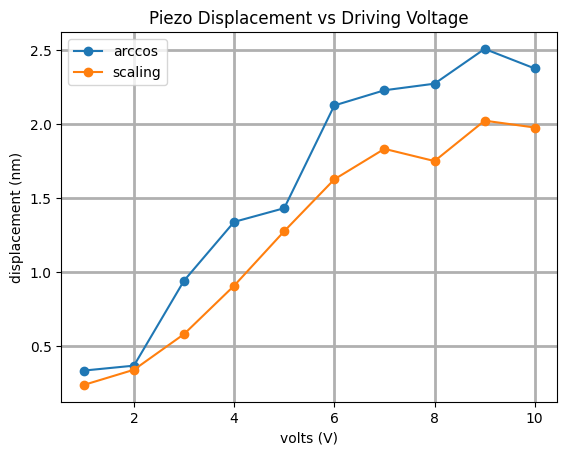

In [12]:
plt.plot(np.linspace(1, 10, 10), np.sqrt(np.mean(np.mean(dpsds, axis = -1), 1) * 108e3) * 1e9 / 2, "o-", label = "arccos")
print(dpsds)
plt.plot(np.linspace(1, 10, 10), (1064 / 2) * np.mean(np.mean(amplitudes, axis = -1), 1) / scaling_factor, "o-", label = "scaling")
plt.xlabel("volts (V)")
plt.ylabel("displacement (nm)")
plt.grid(lw = 2)
plt.legend()
plt.title("Piezo Displacement vs Driving Voltage")
plt.show()